# Compare DEGs and WGCNA Modules

I'm curious if we see any overlap of DEGs with WGCNA modules, and if the overlap makes sense/concurs with the DEG comparison.

## 0. load libraries

In [3]:
library(tidyverse)
library(rtracklayer) # for reading GFF file

## 1. read CSVs

### DEGs
output from [DESeq analysis](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase1_v_phase1/filter_deseq_p1.v.p1.ipynb) and identified in [this code notebook](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase1_v_phase1/volcano_p1.v.p1.ipynb)

In [4]:
# get list of files
files <- list.files(
    path = '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs',
    pattern = '\\.csv$',
    full.names = TRUE
    )

head(files)

[1] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs/DEG_b_c.csv"
[2] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs/DEG_h_b.csv"
[3] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs/DEG_h_c.csv"
[4] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs/DEG_h_w.csv"
[5] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs/DEG_w_b.csv"
[6] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/DEGs/DEG_w_c.csv"

In [8]:
# Read each CSV
degs <- lapply(files, function(f) {
    df <- read.csv(f)
})

# Name each list element
names(degs) <- tools::file_path_sans_ext(basename(files))

# Remove DEG prefix
names(degs) <- sub("DEG_", "", names(degs))

# remove all degs file
degs$p1.all_degs <- NULL

names(degs)

[1] "b_c" "h_b" "h_c" "h_w" "w_b" "w_c"

In [15]:
# combine all dfs in DEG list into one
all.degs <- bind_rows(degs) %>%
dplyr::rename('Gene' = X)
dim(all.degs) # 541 total DEGs for all pairwise comparisons
head(all.degs)

[1] 541   8

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj,pair,DEG_group
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,LOC111120925,191.44305,-4.892009,1.412235,8.362121e-06,0.003642217,C vs. B,C
2,LOC111103173,15.14959,4.191364,2.205467,8.113645e-05,0.016281047,C vs. B,B
3,LOC111105159,57.17908,-5.209114,2.562104,4.785441e-05,0.011315062,C vs. B,C
4,LOC111132252,110.19476,-2.634928,2.039496,2.809993e-04,0.035904919,C vs. B,C
5,LOC111137262,591.06709,3.674337,3.005555,2.185576e-04,0.030313574,C vs. B,B
6,LOC111105069,273.29807,-3.750238,2.841545,1.914828e-04,0.027526121,C vs. B,C


In [13]:
# check number of DEGs per pairwise comparison
all.degs %>% group_by(pair) %>% count()

pair,n
<chr>,<int>
B vs. H,107
B vs. W,82
C vs. B,214
C vs. H,30
C vs. W,60
W vs. H,48


### module info
output from [WGCNA](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase1_v_phase1/wgcna/newRef_wgcna_p1.ipynb)

In [14]:
moduleInfo <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/wgcna/outputs/p1.wgcna_GeneInfo.csv')
head(moduleInfo)

,Gene,ModuleColor,GS.Actual_shell_growth_mg,GS.Actual_tissue_growth_mg,GS.Ratio_tissue_shell_mg,GS.P1_trtmt_code,GS.P1_temp_code,GS.P1_DO_code,GS.both,GS.control,⋯,MMred,MMmagenta,MMtan,MMsalmon,MMpink,MMyellow,MMturquoise,MMgreenyellow,MMblue,MMgreen
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621269,turquoise,0.27424682,0.3582791,0.29229514,-0.14920643,-0.21448305,-0.05651520,-0.26455992,0.05977491,⋯,-0.33803934,0.03903579,0.08308137,-0.6663586,-0.4774152,-0.3366910,0.91160703,0.2427585,-0.01147176,-0.23949648
2,LOC111120925,black,-0.04294156,-0.1084639,-0.17545500,-0.40110317,-0.52242653,-0.17900462,-0.34668741,0.47228699,⋯,0.03494228,-0.17472145,-0.03591849,-0.0605357,-0.5535253,-0.3865442,0.20708515,0.2381314,-0.34905965,-0.16035684
3,LOC144621276,greenyellow,0.32878398,0.3863810,0.24985077,0.08277505,0.10617493,0.03775963,-0.01244986,-0.17543356,⋯,-0.54564066,0.19937653,0.03127251,-0.3251907,-0.4088393,-0.7673879,0.32804341,0.8344366,0.14248051,0.39991437
4,LOC111115920,pink,-0.18930411,-0.4664009,-0.46872840,0.51924356,0.30512331,0.41731743,0.64155708,-0.21920553,⋯,0.13257737,0.09480327,-0.14794939,0.2486783,0.5597128,0.5349486,-0.37122573,-0.2599503,0.14344611,0.06258228
5,LOC144621308,blue,0.08907557,0.1551399,0.09877676,-0.05175412,-0.00699142,-0.05330536,-0.17132811,-0.09234155,⋯,-0.14568006,-0.11875312,-0.20715449,-0.3339040,-0.3451142,-0.2124561,0.04698062,0.2494725,0.22268048,0.01317111
6,LOC111112629,greenyellow,0.17315594,0.1207242,0.01690143,0.27494455,0.17665383,0.21342964,0.08257236,-0.36619296,⋯,-0.34920839,0.23797720,0.02207314,-0.1922233,-0.0373164,-0.2711457,-0.03312545,0.4332788,0.20425568,0.30373935


## 2. match DEGs and WGCNA modules

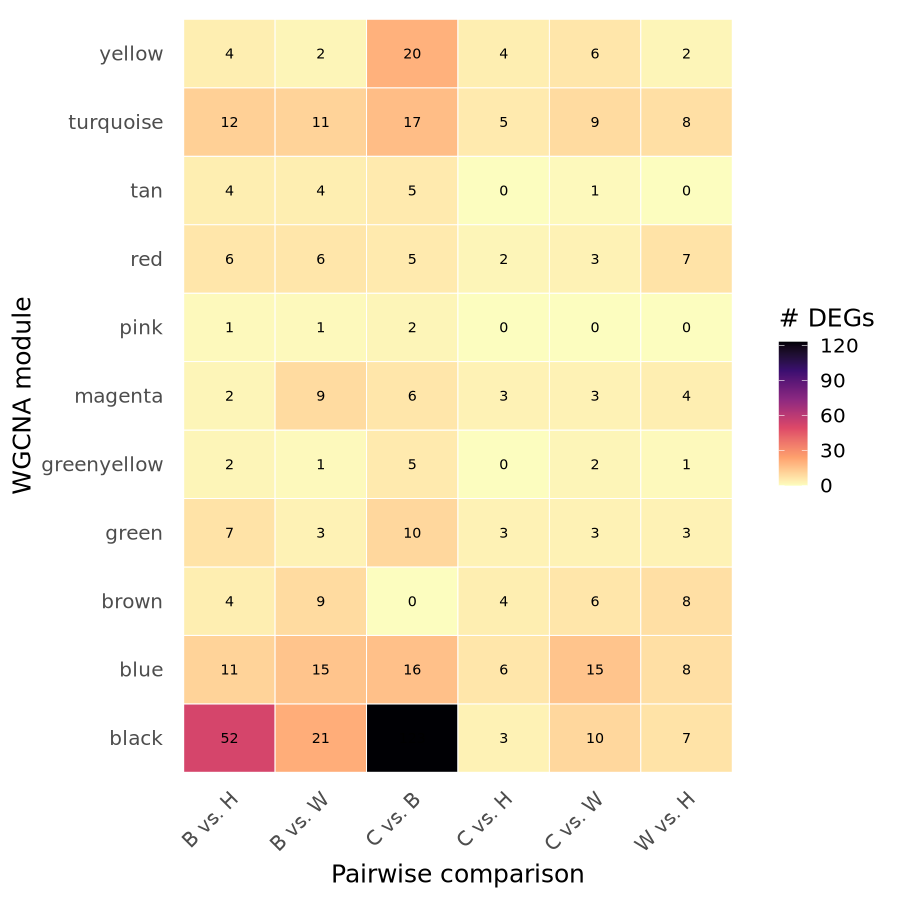

In [24]:
options(repr.plot.width = 7.5, repr.plot.height = 7.5)

# generated with the help of Claude
# 1. Join DEGs to module membership
deg_mod <- all.degs %>%
  inner_join(moduleInfo, by = "Gene")

# 2. Count genes per comparison x module
counts <- deg_mod %>%
  distinct(Gene, pair, ModuleColor) %>%   # guard against duplicate rows
  count(pair, ModuleColor, name = "n_genes")

# 3. Fill in zeros for combinations with no overlap so tiles aren't missing
counts <- counts %>%
  complete(pair, ModuleColor, fill = list(n_genes = 0))

# 4. Plot
ggplot(counts, aes(x = ModuleColor, y = pair, fill = n_genes)) +
  geom_tile(color = "white") +
  geom_text(aes(label = n_genes), size = 3) +
  scale_fill_viridis_c(option = 'magma', direction = -1) +
  labs(x = "WGCNA module", 
       y = "Pairwise comparison", 
       fill = "# DEGs") +
  theme_minimal(base_size = 15) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),
        panel.grid = element_blank()) +
coord_flip()

add module size and number of DEGs in pairwise comparisons to axis labels

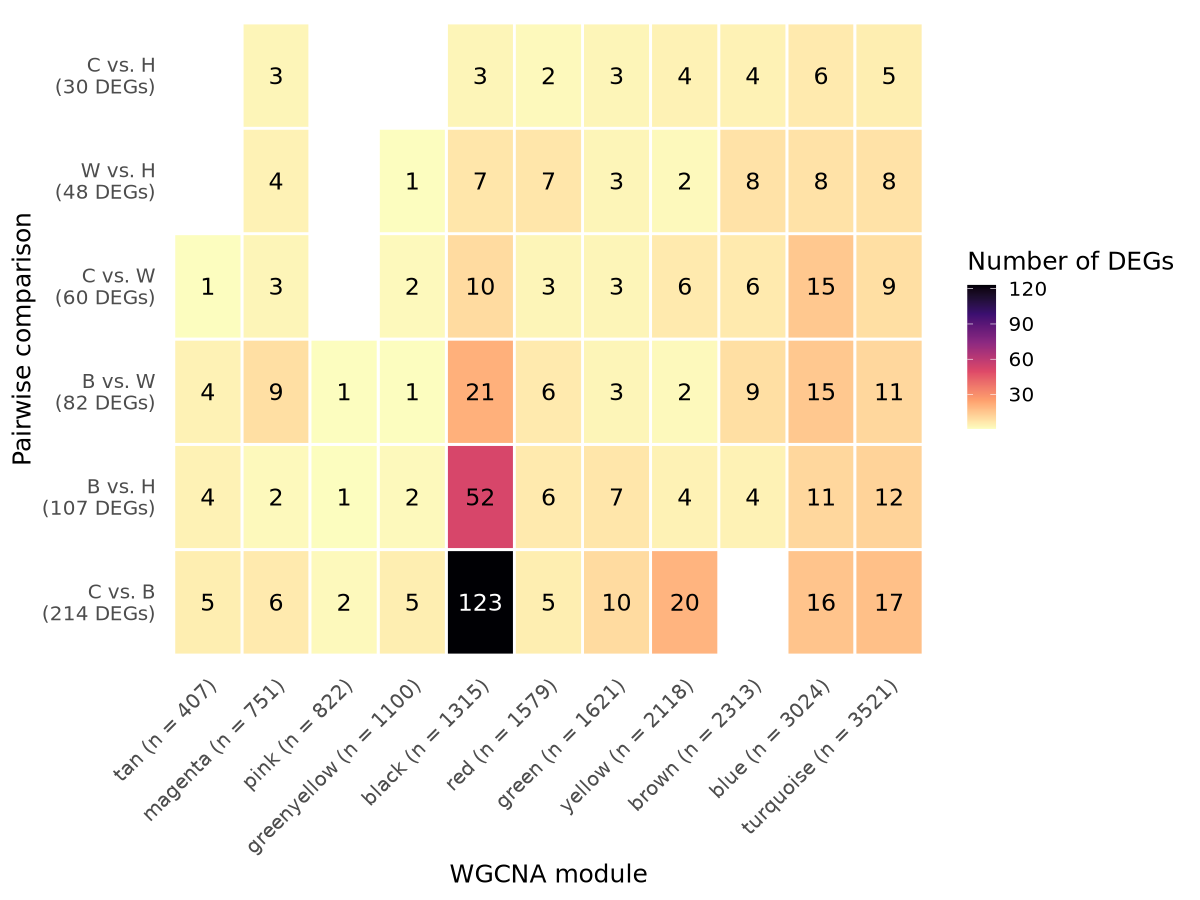

In [39]:
options(repr.plot.width = 10, repr.plot.height = 7.5)

# generated with the help of Claude
# --- Sizes ---
module_sizes <- moduleInfo %>%
  distinct(Gene, ModuleColor) %>%
  count(ModuleColor, name = "module_size")

pair_sizes <- all.degs %>%
  distinct(Gene, pair) %>%
  count(pair, name = "pair_size")

# --- Counts with zero-fill, plus labels ---
counts <- all.degs %>%
  inner_join(moduleInfo, by = "Gene") %>%
  distinct(Gene, pair, ModuleColor) %>%
  count(pair, ModuleColor, name = "n_genes") %>%
  complete(pair, ModuleColor, fill = list(n_genes = 0)) %>%
  left_join(module_sizes, by = "ModuleColor") %>%
  left_join(pair_sizes,   by = "pair") %>%
  mutate(
    module_label = paste0(ModuleColor, " (n = ", module_size, ")"),
    pair_label   = paste0(pair, "\n(", pair_size, " DEGs)"),
    n_plot       = na_if(n_genes, 0),                        # zeros -> NA (no fill, no text)
    text_col     = n_genes > max(n_genes, na.rm = TRUE) / 2  # TRUE = dark tile -> white text
  )

# Order modules by size (largest at top) and pairs by total DEG count
counts <- counts %>%
  mutate(
    module_label = factor(module_label,
                          levels = unique(module_label[order(module_size)])),
    pair_label   = factor(pair_label,
                          levels = unique(pair_label[order(-pair_size)]))
  )

# --- Plot ---
ggplot(counts, aes(x = pair_label, y = module_label, fill = n_plot)) +
  geom_tile(color = "white", linewidth = 0.8) +
  geom_text(aes(label = n_plot, color = text_col),
            size = 5, na.rm = TRUE, show.legend = FALSE) +
  scale_color_manual(values = c("TRUE" = "white", "FALSE" = "black")) +
  scale_fill_viridis_c(option = "magma", direction = -1, na.value = "white") +
  scale_x_discrete(drop = FALSE) +
  scale_y_discrete(drop = FALSE) +
  labs(x = "Pairwise comparison", y = "WGCNA module", fill = "Number of DEGs") +
  theme_minimal(base_size = 15) +
coord_flip() +
  theme(panel.grid = element_blank(),
        axis.text.x = element_text(angle = 45, hjust = 1))

as a reminder, only 4 modules were significantly correlated to factors/traits:
- salmon and red ~ neg. shell growth
- black ~ neg. temperature
- blue ~ pos. warm treatment and shell growth

seems like the majority of DEGs match to the **black module**, despite the black module not being the largest module
- the black module is negatively correlated with temperature
- this is interesting, since the majority of DEGs in comparisons with Both are found in this module

I also see DEGs matching to the **blue module** (C vs. W, B vs. W, B vs. H, C vs. B - all comparisons of different temperatures)
- the blue module is positively correlated with shell growth and warm treatment

what does this actually tell you?
- differentially expressed genes are likely connected? so seeing "global" changes in expression?